In [1]:
import pandas as pd

df = pd.read_csv("../data/admission.csv")
df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,GPA,Research,Chance of Admit
0,295,96,2,4.9,1.7,2.93,0,0.612
1,340,119,3,4.1,1.7,3.76,0,0.708
2,336,96,1,3.2,1.8,3.12,1,0.728
3,337,108,4,3.4,1.3,2.11,0,0.643
4,323,98,1,1.1,1.3,3.40,0,0.524


In [2]:
df.columns = df.columns.str.strip()

In [3]:
X = df.drop("Chance of Admit", axis=1)
y = df["Chance of Admit"]

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [6]:
models = {
    "LR": LinearRegression(),
    "RF": RandomForestRegressor(),
    "XGB": XGBRegressor()
}

In [7]:
from sklearn.metrics import r2_score, mean_absolute_error

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(name)
    print("R2:", r2_score(y_test, pred))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("-"*30)

LR
R2: 0.9027598383788027
MAE: 0.023421396492906706
------------------------------
RF
R2: 0.8548336579850939
MAE: 0.028521199999999997
------------------------------
XGB
R2: 0.8373278694876545
MAE: 0.02966124970674515
------------------------------


In [8]:
print("Feature Importance Insight:")
print("Research feature dominates → testing model without it")

Feature Importance Insight:
Research feature dominates → testing model without it


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error

models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(),
    "XGBoost": XGBRegressor()
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)

    results[name] = {"R2": r2, "MAE": mae}

    print(name)
    print("R2:", r2)
    print("MAE:", mae)
    print("-"*30)

LinearRegression
R2: 0.9027598383788027
MAE: 0.023421396492906706
------------------------------
RandomForest
R2: 0.8520027935048609
MAE: 0.028930349999999997
------------------------------
XGBoost
R2: 0.8373278694876545
MAE: 0.02966124970674515
------------------------------


In [10]:
from sklearn.model_selection import train_test_split

X_new = df.drop(["Chance of Admit", "Research"], axis=1)
y = df["Chance of Admit"]

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y, test_size=0.2, random_state=42
)

In [11]:
from sklearn.ensemble import RandomForestRegressor

rf_new = RandomForestRegressor()
rf_new.fit(X_train_new, y_train_new)

pred_new = rf_new.predict(X_test_new)

In [12]:
from sklearn.metrics import r2_score

print("Original RF vs Without Research")
print("Original R2:", results["RandomForest"]["R2"])
print("New R2:", r2_score(y_test_new, pred_new))

Original RF vs Without Research
Original R2: 0.8520027935048609
New R2: 0.20997488203089287


In [13]:
from sklearn.model_selection import GridSearchCV

<Axes: >

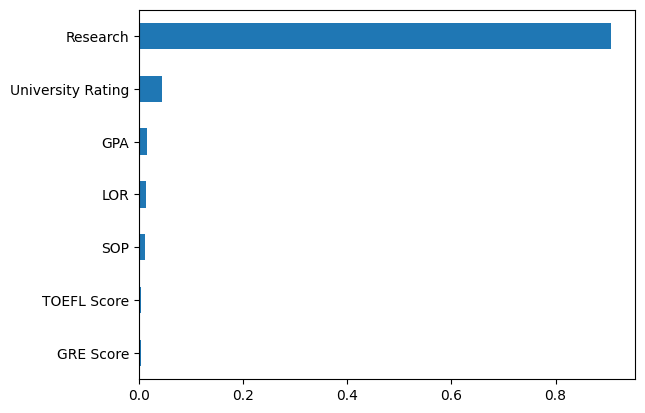

In [14]:
import pandas as pd

feat_imp = pd.Series(model.feature_importances_, index=X.columns)
feat_imp.sort_values().plot(kind="barh")

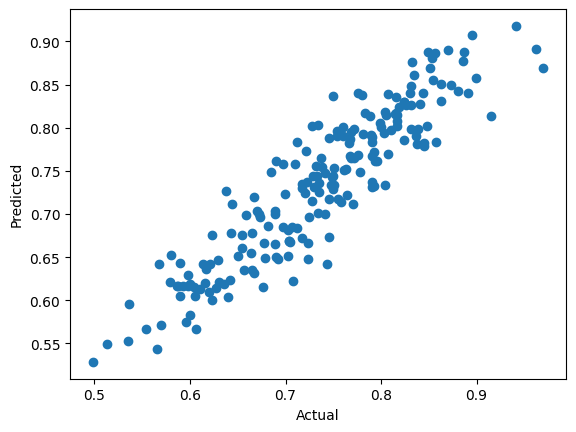

In [15]:
import matplotlib.pyplot as plt

plt.scatter(y_test, pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [16]:
best_model_name = max(results, key=lambda x: results[x]["R2"])
best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: LinearRegression


In [17]:
import os
import pickle

os.makedirs("model", exist_ok=True)

with open("model/model.pkl", "wb") as f:
    pickle.dump(best_model, f)

In [18]:
import pandas as pd

sample = pd.DataFrame(
    [[320, 110, 3, 3.5, 3, 8.5, 1]],
    columns=X.columns
)

pred = model.predict(sample)

print("Prediction:", pred)

Prediction: [0.87904733]
